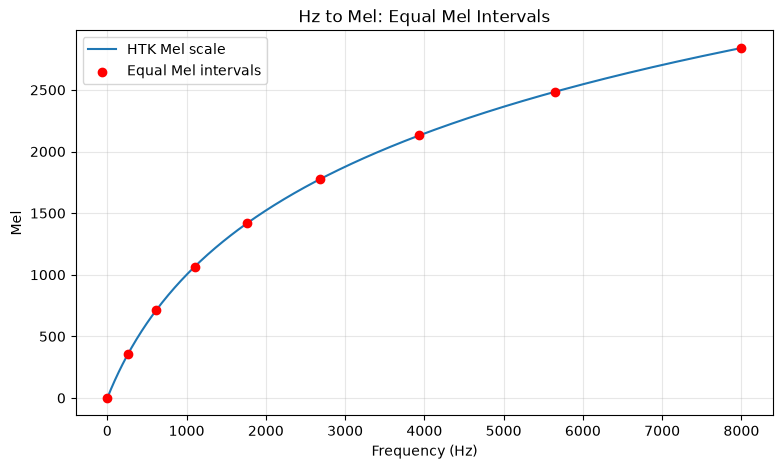

等Mel点对应的Hz位置:
[   0.   259.2  614.3 1101.  1767.8 2681.5 3933.6 5649.2 8000. ]

相邻点的Hz间隔:
[ 259.2  355.1  486.6  666.8  913.7 1252.  1715.6 2350.8]


In [1]:
import numpy as np
import matplotlib.pyplot as plt

#1.生成0-8000Hz的频率点
hz = np.linspace(0,8000,500)

#2.HTK Hz->Mel
mel = 2595 * np.log10(1 + hz/700)

#3.在Mel坐标上均匀选取9个点
mel_points = np.linspace(mel[0],mel[-1],9)

#4.通过HTK反变换得到对应Hz位置
hz_points = 700 * (10 ** (mel_points / 2595) - 1)

#5. 绘图
fig, ax = plt.subplots(figsize=(9,5))

ax.plot(hz,mel,label="HTK Mel scale")
ax.scatter(
    hz_points,
    mel_points,
    color="red",
    zorder=3,
    label="Equal Mel intervals"
)

ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Mel")
ax.set_title("Hz to Mel: Equal Mel Intervals")
ax.grid(alpha=0.3)
ax.legend()

plt.show()

# 6. 比较对应的Hz间隔
print("等Mel点对应的Hz位置:")
print(np.round(hz_points, 1))

print("\n相邻点的Hz间隔:")
print(np.round(np.diff(hz_points), 1))

In [2]:
#手写与librosa函数对照
import sys
from pathlib import Path
import importlib

import numpy as np
import librosa

root = Path.cwd().resolve()
if root.name.lower() == "notebooks":
    root = root.parent

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import src.features as features

# 在Notebook中重新读取修改后的features.py
importlib.reload(features)

hz = np.array([0,100,500,1000,2000,8000])

#HTK对照
ours_htk = features.hz_to_mel(hz,scale="htk")
lib_htk = librosa.hz_to_mel(hz,htk=True)

#Slaney对照
ours_slaney = features.hz_to_mel(hz,scale="slaney")
lib_slaney = librosa.hz_to_mel(hz,htk=False)

print("HTK 最大误差:", np.max(np.abs(ours_htk - lib_htk)))
print("Slaney 最大误差:", np.max(np.abs(ours_slaney - lib_slaney)))

print("\nHz:", hz)
print("HTK Mel:", np.round(ours_htk, 3))
print("Slaney Mel:", np.round(ours_slaney, 3))

assert np.allclose(ours_htk, lib_htk, atol=1e-9)
assert np.allclose(ours_slaney, lib_slaney, atol=1e-9)

assert features.hz_to_mel(0) == 0.0

print("\nHz → Mel 两套约定均通过对照")

HTK 最大误差: 0.0
Slaney 最大误差: 3.552713678800501e-15

Hz: [   0  100  500 1000 2000 8000]
HTK Mel: [   0.     150.489  607.446  999.986 1521.36  2840.023]
Slaney Mel: [ 0.     1.5    7.5   15.    25.082 45.246]

Hz → Mel 两套约定均通过对照


In [3]:
#异常处理
for value in [-100,float("nan"),float("inf")]:
    try:
        features.hz_to_mel(value)
    except ValueError:
        print(f"{value}:正确拒绝")
    else:
        raise AssertionError(f"{value}: 未拒绝异常输入")

-100:正确拒绝
nan:正确拒绝
inf:正确拒绝


原始功率: [1.e+00 1.e-02 1.e-04 0.e+00]
对数压缩后(dB): [   0.  -20.  -40. -100.]


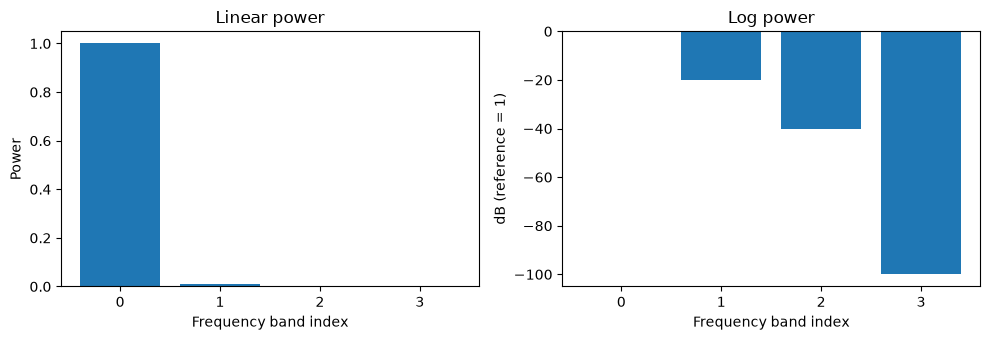

In [4]:
#验证动态范围压缩
import numpy as np
import matplotlib.pyplot as plt

power = np.array([1.0,1e-2,1e-4,0.0])

eps = 1e-10
log_power_db = 10 * np.log10(np.maximum(power, eps))

print("原始功率:", power)
print("对数压缩后(dB):", log_power_db)

fig,axes = plt.subplots(1,2,figsize=(10,3.5))

axes[0].bar(range(len(power)), power)
axes[0].set_title("Linear power")
axes[0].set_ylabel("Power")

axes[1].bar(range(len(power)), log_power_db)
axes[1].set_title("Log power")
axes[1].set_ylabel("dB (reference = 1)")

for ax in axes:
    ax.set_xlabel("Frequency band index")
    ax.set_xticks(range(len(power)))

fig.tight_layout()
plt.show()

In [1]:
#验证Mel滤波器组的矩阵形状
import numpy as np
import librosa

#1.固定参数
sr = 32000
n_fft = 1024
n_mels = 80

#2.使用库函数构造Mel滤波器组
mel_filter = librosa.filters.mel(
    sr = sr,
    n_fft=n_fft,
    n_mels=n_mels,
    fmin=0,
    fmax=16000,
    htk=False,
    norm="slaney"
)

#3.构造模拟的非负功率谱
rng = np.random.default_rng(2026)

power_spectrogram = rng.random(
    (n_fft // 2 + 1, 10)
)

#4.Mel滤波器组加权求和
mel_power = mel_filter @ power_spectrogram

print("Mel滤波器组形状:", mel_filter.shape)
print("功率谱形状:", power_spectrogram.shape)
print("Mel功率谱形状:", mel_power.shape)

# 5. 验收
assert mel_filter.shape == (80, 513)
assert power_spectrogram.shape == (513, 10)
assert mel_power.shape == (80, 10)
assert np.all(np.isfinite(mel_power))
assert np.all(mel_power >= 0)

print("Mel矩阵乘法检查通过")

Mel滤波器组形状: (80, 513)
功率谱形状: (513, 10)
Mel功率谱形状: (80, 10)
Mel矩阵乘法检查通过


In [2]:
#用模拟语音进行测试
import sys
import importlib
from pathlib import Path
import numpy as np
import librosa

root = Path.cwd().resolve()

if root.name.lower() == "notebooks":
    root = root.parent

if not (root / "src" / "features.py").is_file():
    root = Path(r"D:\Projects\speech-ai-learning")

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import src.features as features
importlib.reload(features)

#1.构造1秒440Hz正弦波
sr = 32000
t = np.arange(sr) / sr
waveform = 0.2 * np.sin(2*np.pi*440*t)

#2.调用自己的教学函数
ours = features.waveform_to_mel(
    waveform,
    sr=sr,
    n_fft=1024,
    win_length=800,
    hop_length=160,
    window="hann",
    center=True,
    pad_mode="constant",
    n_mels=80,
    fmin=0,
    fmax=16000,
    htk=False,
    norm="slaney",
    eps=1e-10
)

# 3. 使用librosa的一站式接口作为参考
reference_power = librosa.feature.melspectrogram(
    y=waveform,
    sr=sr,
    n_fft=1024,
    win_length=800,
    hop_length=160,
    window="hann",
    center=True,
    pad_mode="constant",
    power=2.0,
    n_mels=80,
    fmin=0,
    fmax=16000,
    htk=False,
    norm="slaney",
    dtype=np.float64,
)

reference = 10.0 * np.log10(
    np.maximum(reference_power, 1e-10)
)

#4.对比
print("waveform shape:",waveform.shape)
print("ours shape:",ours.shape)
print("reference shape:", reference.shape)
print("最大绝对误差：",np.max(np.abs(ours-reference)))

assert ours.shape == (80, 201)
assert ours.shape == reference.shape
assert np.allclose(ours, reference, atol=1e-5, rtol=1e-5)
assert np.all(np.isfinite(ours))

print("waveform_to_mel 数值对照通过")

#5.零信号测试
silence = np.zeros(sr,dtype=np.float64)
silence_mel = features.waveform_to_mel(silence,sr=sr)

assert np.all(np.isfinite(silence_mel))
assert np.allclose(silence_mel, -100.0)

print("零信号数值稳定性测试通过")

waveform shape: (32000,)
ours shape: (80, 201)
reference shape: (80, 201)
最大绝对误差： 0.0
waveform_to_mel 数值对照通过
零信号数值稳定性测试通过


waveform shape: (202752,)
STFT power shape: (513, 1268)
Log-Mel shape: (80, 1268)
librosa最大误差: 0.0


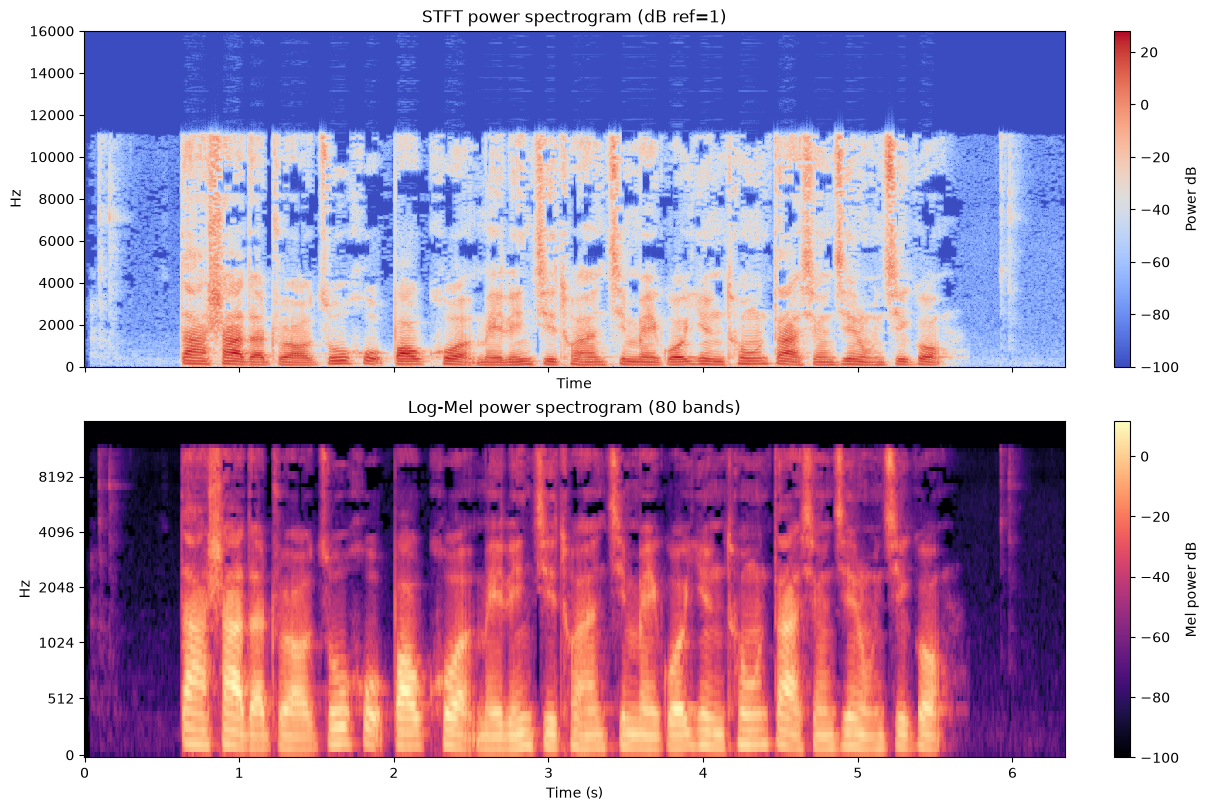

对照图已保存: D:\Projects\speech-ai-learning\results\w06d2_stft_vs_logmel.png
参数配置已保存: D:\Projects\speech-ai-learning\results\w06d2_feature_config.json


In [4]:
#真实语音特征对照
from pathlib import Path
import json
import importlib
import sys

import numpy as np
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt

#项目根目录
root = Path.cwd().resolve()
if root.name.lower() == "notebooks":
    root = root.parent

if not (root / "src" / "features.py").is_file():
    root = Path(r"D:\Projects\speech-ai-learning")

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import src.features as features
importlib.reload(features)

#1.读取W5D6保存的clean真实语音
audio_path = root / "data/derived/w05_snr/demo_clean.wav"

assert audio_path.is_file(),f"找不到音频{audio_path}"

audio,sr = sf.read(
    audio_path,
    dtype="float64",
    always_2d=True
)

assert audio.shape[1] == 1,"本实验要求单声道"

waveform = audio[:,0]

assert sr == 32000
assert np.isfinite(waveform).all()

#2.明确所有特征参数
config = {
    "feature_type": "teaching_logmel_power_db",
    "source_parent_uid": "common_voice_zh-CN_27897382",
    "source_condition": "clean",
    "sample_rate": sr,
    "n_fft": 1024,
    "win_length": 800,
    "hop_length": 160,
    "window": "hann",
    "center": True,
    "pad_mode": "constant",
    "n_mels": 80,
    "fmin": 0.0,
    "fmax": 16000.0,
    "htk": False,
    "norm": "slaney",
    "spectrum_power": 2.0,
    "log_base": 10,
    "log_multiplier": 10.0,
    "reference_power": 1.0,
    "eps": 1e-10,
    "top_db": None,
    "whisper_compatible": False
}

#3.线性频率STFT功率谱
D = librosa.stft(
    y=waveform,
    n_fft=config["n_fft"],
    win_length=config["win_length"],
    hop_length=config["hop_length"],
    window=config["window"],
    center=config["center"],
    pad_mode=config["pad_mode"],
)

power_spec = np.abs(D) ** 2

stft_db = 10 * np.log10(
    np.maximum(power_spec, config["eps"])
)

#4.自定义函数计算Log-Mel
mel_db = features.waveform_to_mel(
    waveform,
    sr=sr,
    n_fft=config["n_fft"],
    win_length=config["win_length"],
    hop_length=config["hop_length"],
    window=config["window"],
    center=config["center"],
    pad_mode=config["pad_mode"],
    n_mels=config["n_mels"],
    fmin=config["fmin"],
    fmax=config["fmax"],
    htk=config["htk"],
    norm=config["norm"],
    eps=config["eps"],
)

#5.与librosa参考接口再次对照
mel_ref_power = librosa.feature.melspectrogram(
    y=waveform,
    sr=sr,
    n_fft=config["n_fft"],
    win_length=config["win_length"],
    hop_length=config["hop_length"],
    window=config["window"],
    center=config["center"],
    pad_mode=config["pad_mode"],
    power=config["spectrum_power"],
    n_mels=config["n_mels"],
    fmin=config["fmin"],
    fmax=config["fmax"],
    htk=config["htk"],
    norm=config["norm"],
    dtype=np.float64,
)

mel_ref_db = 10 * np.log10(
    np.maximum(mel_ref_power,config["eps"])
)

max_error = float(np.max(np.abs(mel_db - mel_ref_db)))

assert mel_db.shape[0] == config["n_mels"]
assert mel_db.shape[1] == D.shape[1]
assert np.isfinite(stft_db).all()
assert np.isfinite(mel_db).all()
assert np.allclose(mel_db,mel_ref_db,atol=1e-5)

print("waveform shape:", waveform.shape)
print("STFT power shape:", power_spec.shape)
print("Log-Mel shape:", mel_db.shape)
print("librosa最大误差:", max_error)

#6.绘制STFT与Log-Mel对照图
fig,axes = plt.subplots(
    2,1,
    figsize=(12,8),
    sharex=True,
    constrained_layout=True
)

img1 = librosa.display.specshow(
    stft_db,
    sr=sr,
    hop_length=config["hop_length"],
    x_axis="time",
    y_axis="linear",
    ax=axes[0]
)
axes[0].set_title("STFT power spectrogram (dB ref=1)")
fig.colorbar(img1,ax=axes[0],label="Power dB")

img2 = librosa.display.specshow(
    mel_db,
    sr=sr,
    hop_length=config["hop_length"],
    x_axis="time",
    y_axis="mel",
    fmin=config["fmin"],
    fmax=config["fmax"],
    ax=axes[1]
)
axes[1].set_title("Log-Mel power spectrogram (80 bands)")
fig.colorbar(img2, ax=axes[1], label="Mel power dB")

axes[1].set_xlabel("Time (s)")

#7.保存图像与参数
results_dir = root / "results"
results_dir.mkdir(parents=True,exist_ok=True)

figure_path = results_dir / "w06d2_stft_vs_logmel.png"
config_path = results_dir / "w06d2_feature_config.json"

fig.savefig(figure_path,dpi=180)
plt.show()

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config,f,ensure_ascii=False,indent=2)

print("对照图已保存:", figure_path)
print("参数配置已保存:", config_path)